# Qualitative test of local descriptors

Uses the functions in `descriptors.py` (it must be in the same folder as the notebook).

- **1 image** → detected keypoints (circle = scale, line = orientation) and descriptor info.
- **2 images** → also matches them and validates with RANSAC (homography):
  <span style="color:green">green</span> = consistent matches, <span style="color:red">red</span> = errors.

Each descriptor uses the matching detector: **ORB → ORB**, **AKAZE → AKAZE**, everything else → **SIFT**.

## Parameters

In [25]:


DESCRIPTORS = ["sift", "rootsift", "color_sift", "pca_sift", "gloh", "surf",
               "daisy", "lbp", "orb", "latch", "akaze"]   # or e.g. ["sift", "orb", "latch"]

N_KEYPOINTS = 500      # maximum number of keypoints per image
RATIO = 0.8            # Lowe's ratio test
RANSAC_PX = 5.0        # RANSAC reprojection threshold (px)
MAX_SIDE = 1200        # downscale images larger than this (px)
RICH = True            # True: circles with scale and orientation | False: dots only
FIG_WIDTH = 16         # figure width (inches)

## Setup

In [26]:
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
BBDD_DIR = DATA_DIR / "BBDD"
QSD1_DIR = DATA_DIR / "qsd1_w4"

IMAGES = [QSD1_DIR / "00001.jpg", BBDD_DIR / "bbdd_00150.jpg"]

In [27]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import descriptors as D

BINARY = {"orb", "latch", "akaze"}
DETECTOR_FOR = {"orb": "orb", "akaze": "akaze"}          # everything else: SIFT


def make_detector(name):
    feat = cv2 if hasattr(cv2, "AKAZE_create") else cv2.xfeatures2d   # OpenCV 5
    return {"sift": lambda: cv2.SIFT_create(N_KEYPOINTS),
            "orb": lambda: cv2.ORB_create(N_KEYPOINTS),
            "akaze": lambda: feat.AKAZE_create()}[name]()


def detect(det_name, img):
    kps = make_detector(det_name).detect(img, None)
    return sorted(kps, key=lambda k: -k.response)[:N_KEYPOINTS]


def run(desc_name, imgs):
    """Detect + describe on each image; if there are 2, match + RANSAC."""
    det_name = DETECTOR_FOR.get(desc_name, "sift")
    fn = getattr(D, desc_name)
    r = {"desc": desc_name, "det": det_name, "kps": [], "d": [], "t": []}
    pca_model = None
    for img in imgs:
        kps = detect(det_name, img)
        t = time.time()
        if desc_name == "pca_sift":                 # same PCA projection for both images
            if pca_model is None:
                d, pca_model = fn(img, kps, return_pca=True)
            else:
                d = fn(img, kps, pca=pca_model)
        else:
            d = fn(img, kps)
        r["t"].append(time.time() - t)
        r["kps"].append(kps)
        r["d"].append(d)

    if len(imgs) == 2:
        d1, d2 = r["d"]
        norm = cv2.NORM_HAMMING if desc_name in BINARY else cv2.NORM_L2
        if norm == cv2.NORM_L2:
            d1, d2 = d1.astype(np.float32), d2.astype(np.float32)
        knn = cv2.BFMatcher(norm).knnMatch(d1, d2, k=2) if len(d1) and len(d2) > 1 else []
        ms = [m[0] for m in knn if len(m) == 2 and m[0].distance < RATIO * m[1].distance]
        inl = np.zeros(len(ms), bool)
        if len(ms) >= 4:
            p1 = np.float32([r["kps"][0][m.queryIdx].pt for m in ms])
            p2 = np.float32([r["kps"][1][m.trainIdx].pt for m in ms])
            _, mask = cv2.findHomography(p1, p2, cv2.RANSAC, RANSAC_PX)
            if mask is not None:
                inl = mask.ravel().astype(bool)
        r["matches"], r["inliers"] = ms, inl
    return r


def draw_kps(img, kps, rich=True):
    if rich:
        return cv2.drawKeypoints(img, kps, None, (0, 255, 255),
                                 cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    out = img.copy()
    for k in kps:
        cv2.circle(out, tuple(int(round(v)) for v in k.pt), 3, (0, 255, 255), -1, cv2.LINE_AA)
    return out


def info(r):
    d = r["d"][0]
    kind = "bytes, Hamming" if d.dtype == np.uint8 else "floats, L2"
    s = f"{r['desc'].upper()}  (detector {r['det'].upper()}, D = {d.shape[1]} {kind})"
    for i, (k, t) in enumerate(zip(r["kps"], r["t"])):
        s += f"\nImage {i + 1}: {len(k)} keypoints -> {len(r['d'][i])} descriptors in {t * 1000:.0f} ms"
    return s


def show_keypoints(name):
    n = len(imgs)
    fig, axes = plt.subplots(1, n, figsize=(FIG_WIDTH, FIG_WIDTH / n * 0.75), squeeze=False)
    for i, ax in enumerate(axes[0]):
        ax.imshow(cv2.cvtColor(draw_kps(imgs[i], r["kps"][i], RICH), cv2.COLOR_BGR2RGB))
        ax.set_title(f"Image {i + 1}: {len(r['kps'][i])} keypoints")
        ax.axis("off")
    fig.suptitle(info(r), fontsize=11, x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


def show_matches(name):
    a = draw_kps(imgs[0], r["kps"][0], rich=False)
    b = draw_kps(imgs[1], r["kps"][1], rich=False)
    H = max(a.shape[0], b.shape[0])
    pad = lambda x: cv2.copyMakeBorder(x, 0, H - x.shape[0], 0, 0, cv2.BORDER_CONSTANT)
    canvas = np.hstack([pad(a), pad(b)])
    off = a.shape[1]
    lw = max(1, round(canvas.shape[1] / 1200))
    for m, ok in sorted(zip(r["matches"], r["inliers"]), key=lambda x: x[1]):   # inliers on top
        p = tuple(int(round(v)) for v in r["kps"][0][m.queryIdx].pt)
        q = r["kps"][1][m.trainIdx].pt
        cv2.line(canvas, p, (int(round(q[0])) + off, int(round(q[1]))),
                 (80, 220, 80) if ok else (60, 60, 255), lw, cv2.LINE_AA)
    n_m, n_in = len(r["matches"]), int(r["inliers"].sum())
    pct = 100 * n_in / n_m if n_m else 0
    plt.figure(figsize=(FIG_WIDTH, FIG_WIDTH * canvas.shape[0] / canvas.shape[1]))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.title(f"{info(r)}\nMatches (ratio test): {n_m}   |   RANSAC inliers: {n_in} ({pct:.0f}%)",
              fontsize=11, loc="left")
    plt.axis("off")
    plt.show()

## Load images

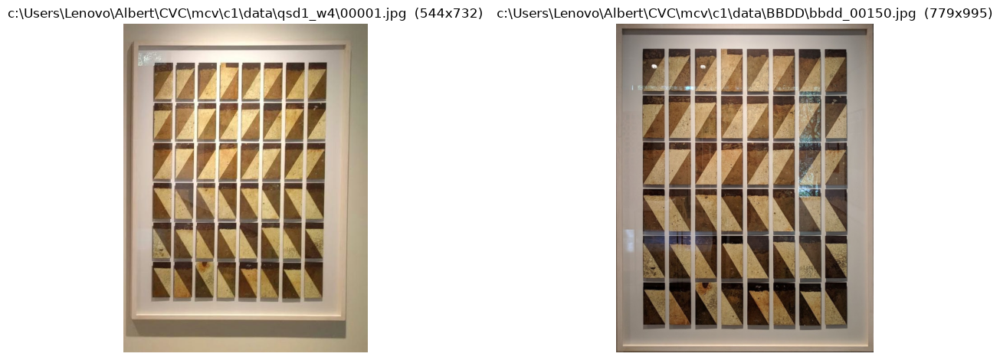

In [28]:
imgs = []
for path in IMAGES:
    im = cv2.imread(path, cv2.IMREAD_COLOR)
    assert im is not None, f"cannot read {path}"
    s = min(1.0, MAX_SIDE / max(im.shape[:2]))
    imgs.append(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else im)

fig, axes = plt.subplots(1, len(imgs), figsize=(FIG_WIDTH, FIG_WIDTH / len(imgs) * 0.6), squeeze=False)
for ax, im, path in zip(axes[0], imgs, IMAGES):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{path}  ({im.shape[1]}x{im.shape[0]})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Compute all descriptors

In [29]:
results = {}
for name in DESCRIPTORS:
    results[name] = run(name, imgs)

header = f"{'descriptor':11s} {'detector':8s} {'D':>5s} {'type':8s} " + \
         " ".join(f"{'kps'+str(i+1):>6s} {'ms'+str(i+1):>6s}" for i in range(len(imgs)))
if len(imgs) == 2:
    header += f" {'matches':>8s} {'inliers':>8s} {'%':>5s}"
print(header)
print("-" * len(header))
for name, r in results.items():
    row = f"{name:11s} {r['det']:8s} {r['d'][0].shape[1]:5d} {str(r['d'][0].dtype):8s} " + \
          " ".join(f"{len(k):6d} {t*1000:6.0f}" for k, t in zip(r["kps"], r["t"]))
    if len(imgs) == 2:
        n_m, n_in = len(r["matches"]), int(r["inliers"].sum())
        row += f" {n_m:8d} {n_in:8d} {100*n_in/max(n_m,1):5.0f}"
    print(row)

descriptor  detector     D type       kps1    ms1   kps2    ms2  matches  inliers     %
---------------------------------------------------------------------------------------
sift        sift       128 float32     500    149    500    162      173       82    47
rootsift    sift       128 float32     500    154    500    138      146       81    55
color_sift  sift       384 float32     500    408    500    435       96       61    64
pca_sift    sift        36 float32     500  12369    500     36      151       48    32
gloh        sift       272 float32     500     77    500     78      112       49    44
surf        sift        64 float32     500     52    500     54      117       42    36
daisy       sift       200 float32     500    662    500    731      187       82    44
lbp         sift       944 float32     500     58    500     61       17       10    59
orb         orb         32 uint8       500     56    500     55      147       37    25
latch       sift        32 uint8

## Keypoints

The keypoints only depend on the detector: all descriptors that use SIFT see the same points.
That is why only one figure is shown per detector here.

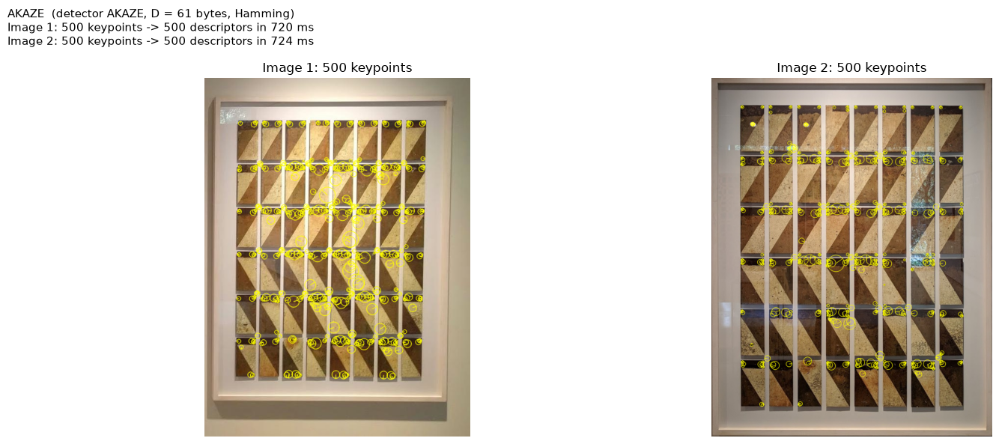

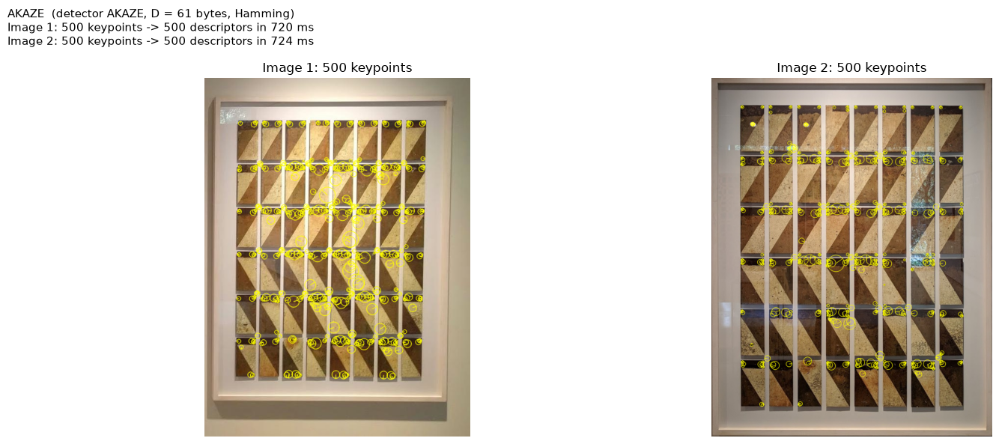

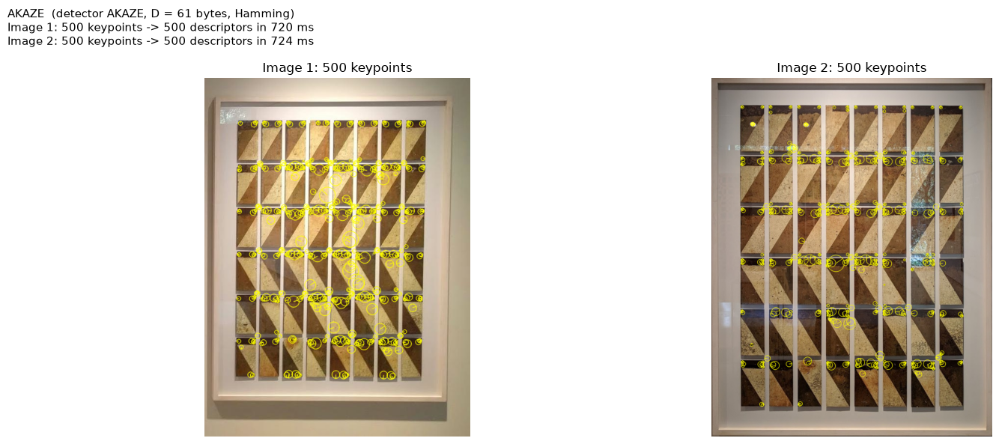

In [30]:
shown = set()
for name in DESCRIPTORS:
    det = results[name]["det"]
    if det not in shown:
        shown.add(det)
        show_keypoints(name)

## Matches (only with 2 images)

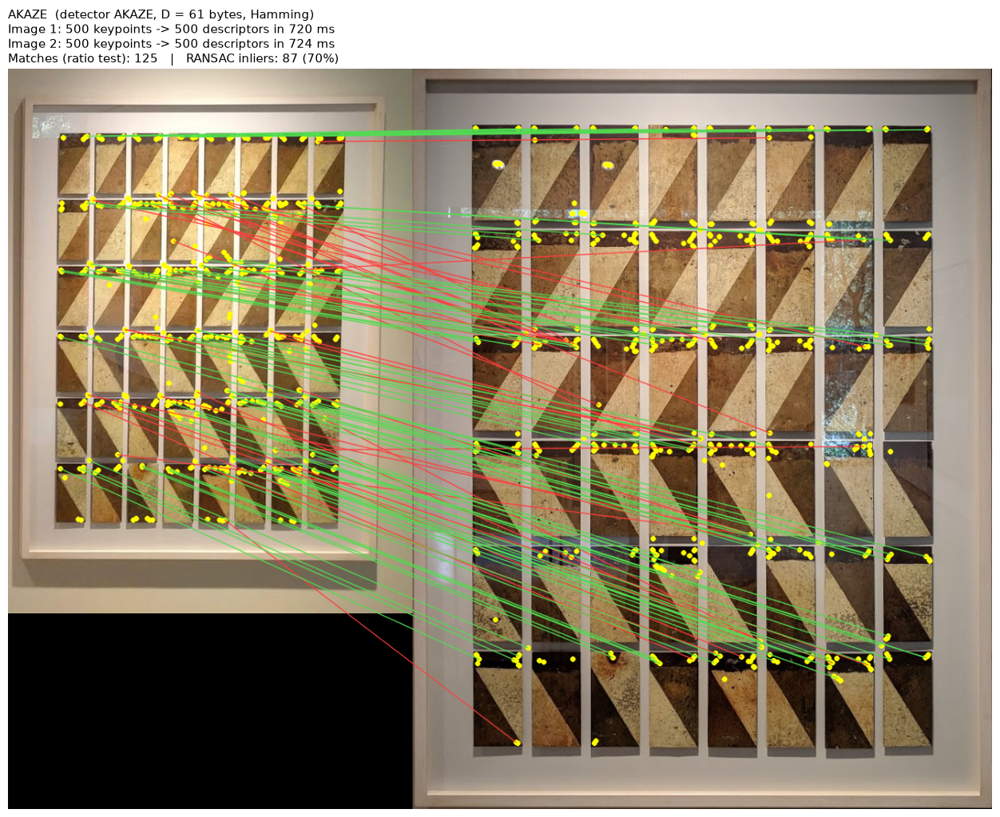

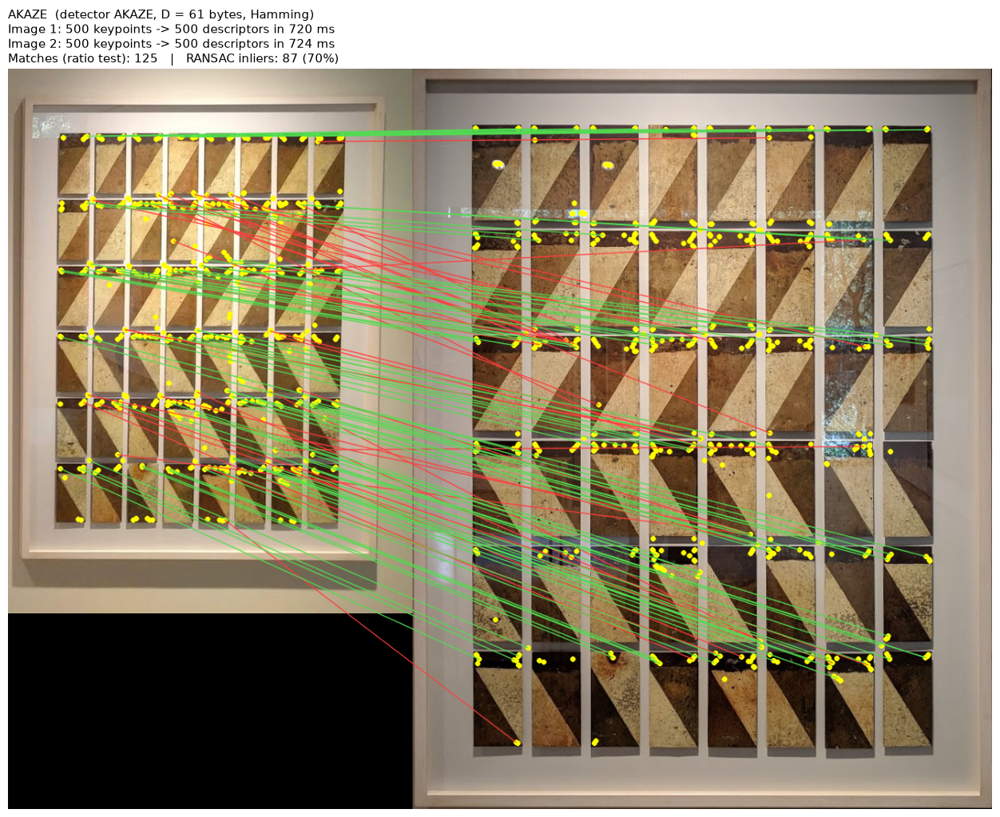

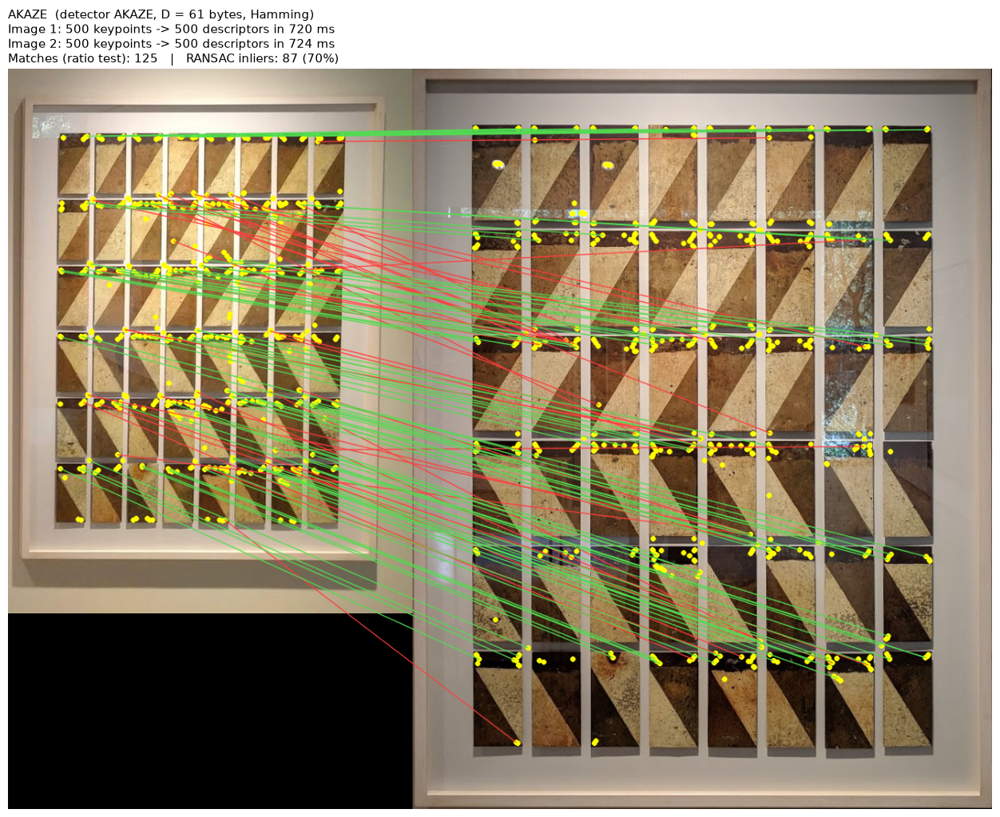

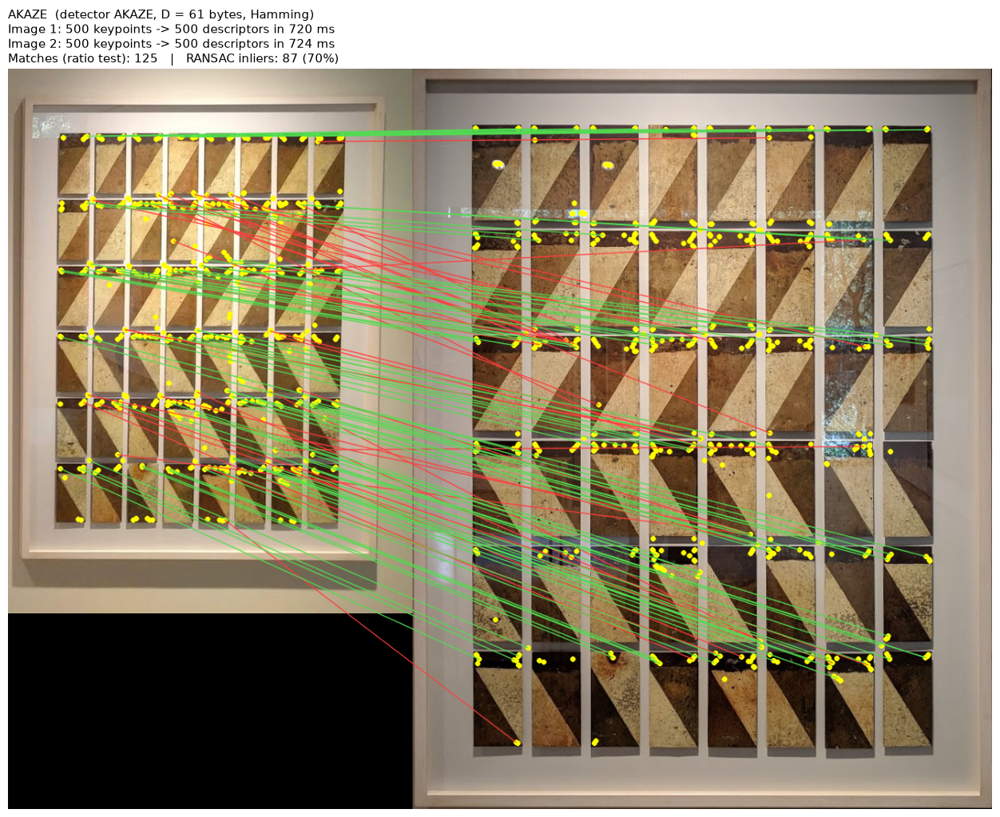

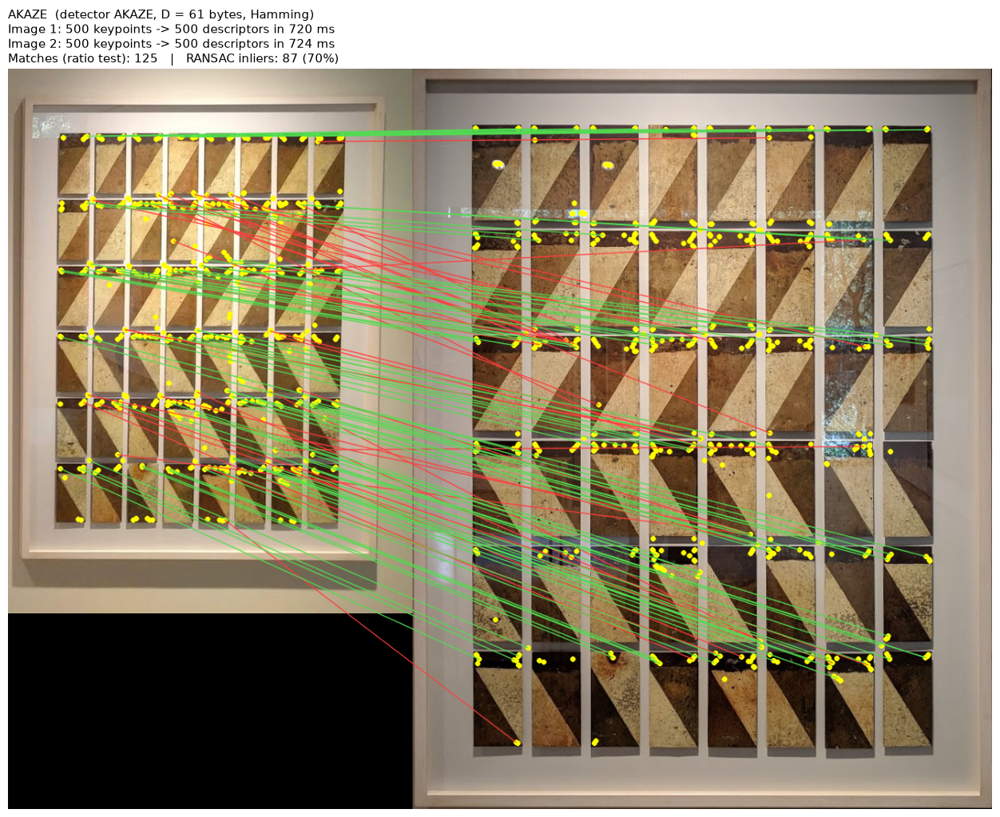

...

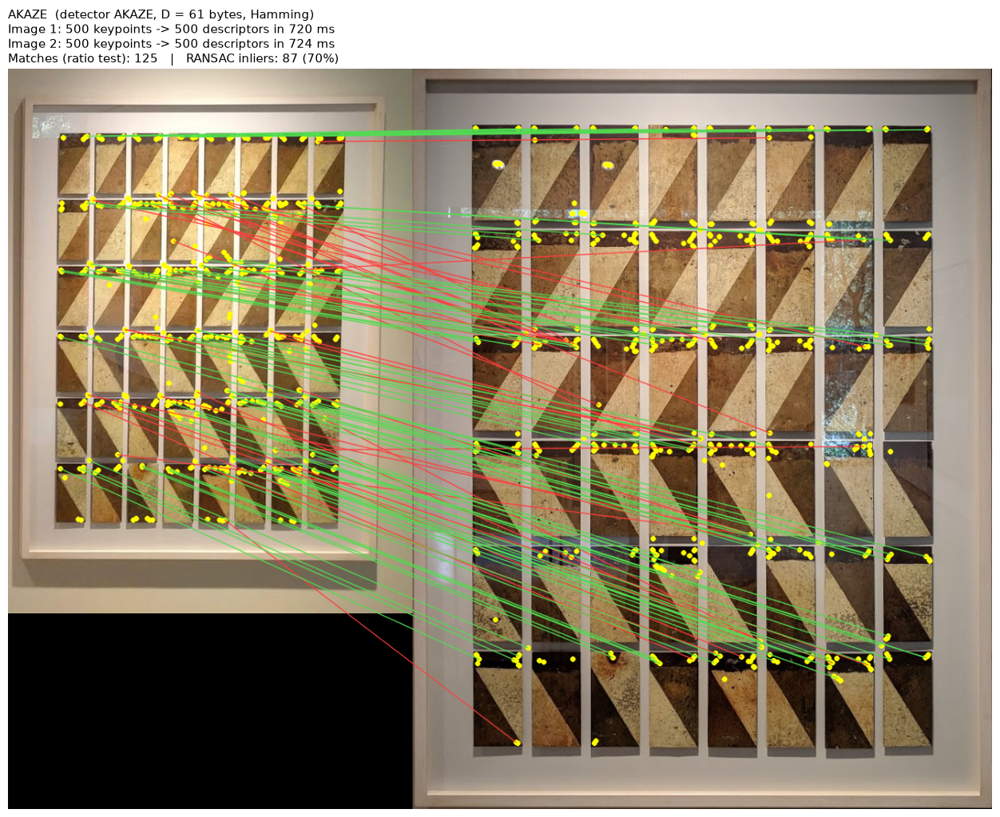

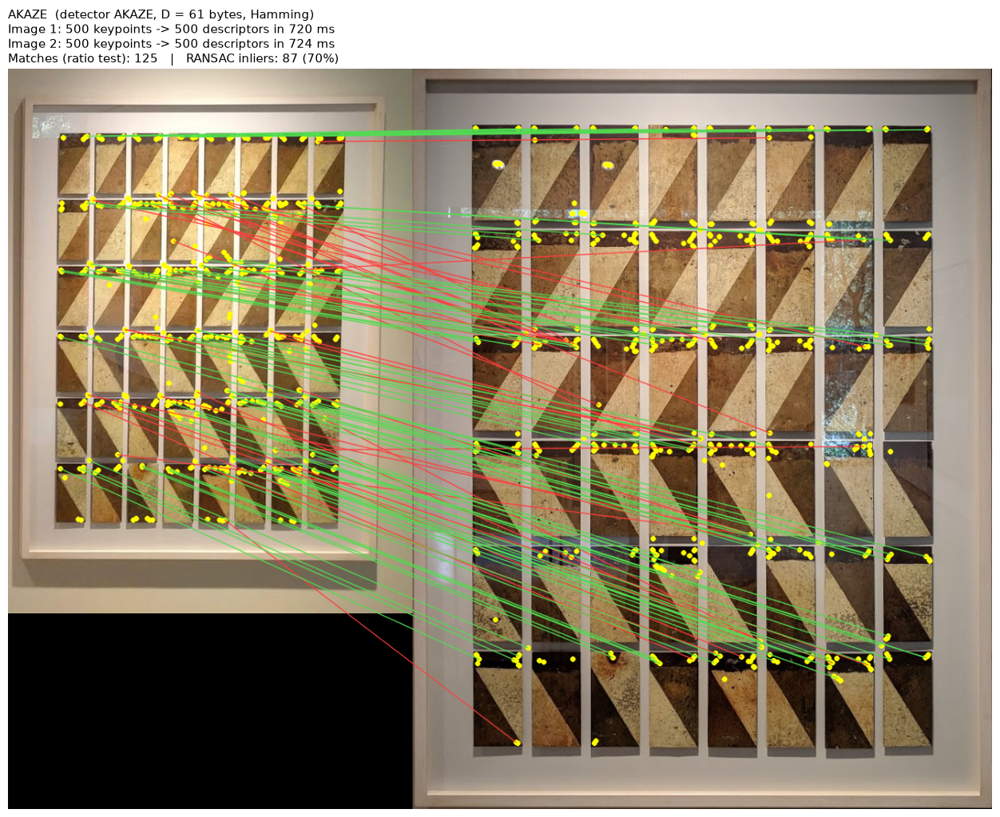

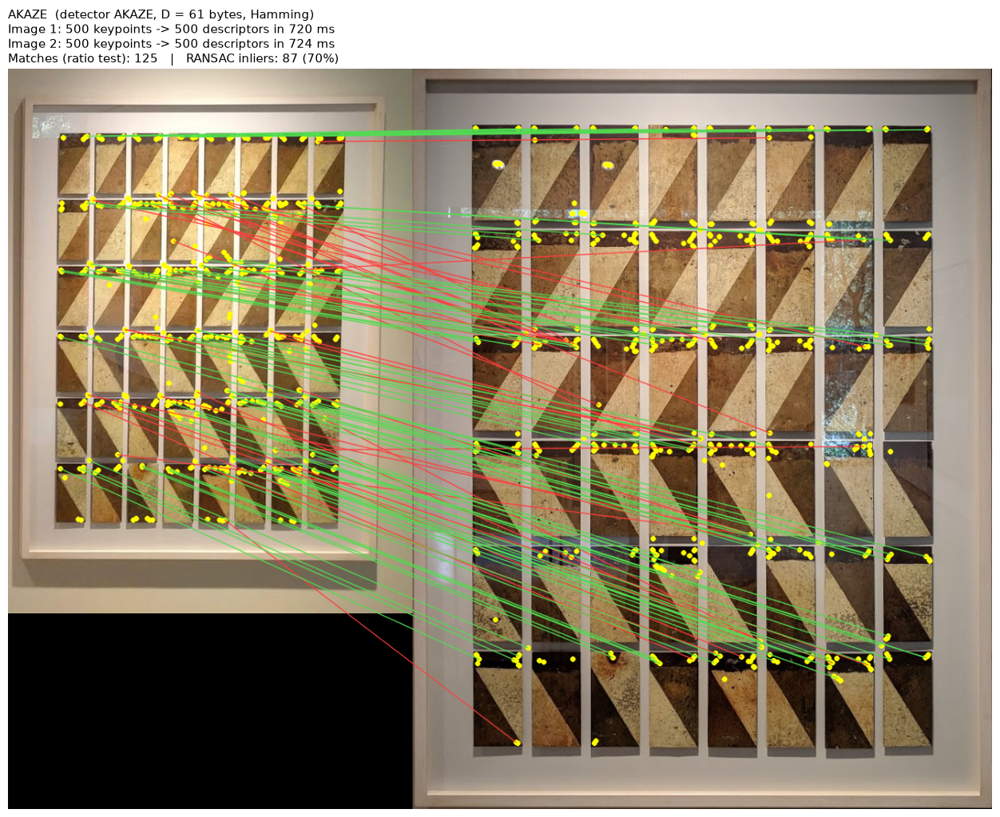

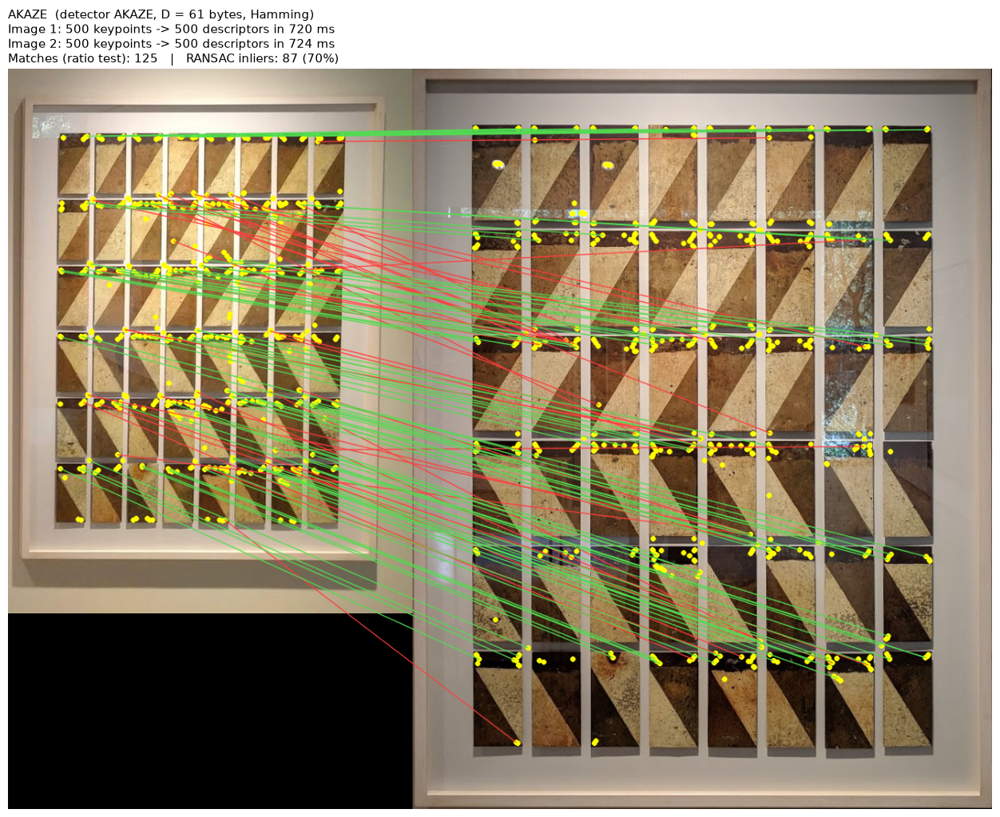

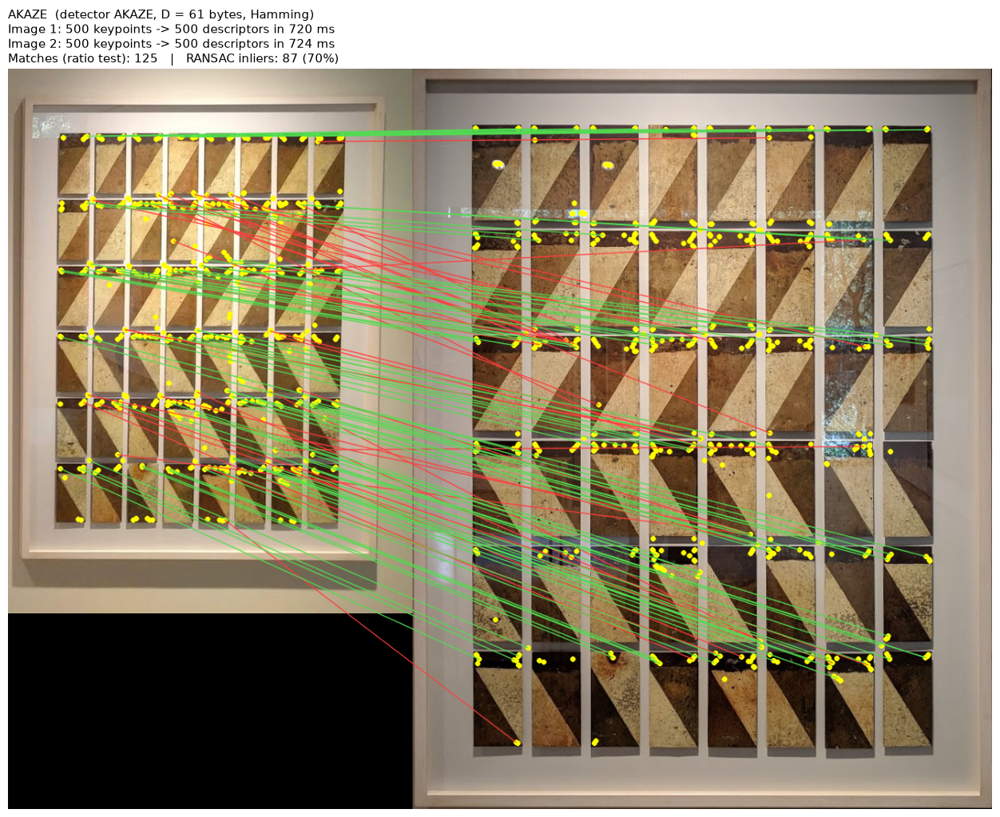

In [31]:
if len(imgs) == 2:
    for name in DESCRIPTORS:
        show_matches(name)
else:
    print("Put 2 images in IMAGES to see the matches.")

## Look at a single descriptor

Change the name and rerun the cell.

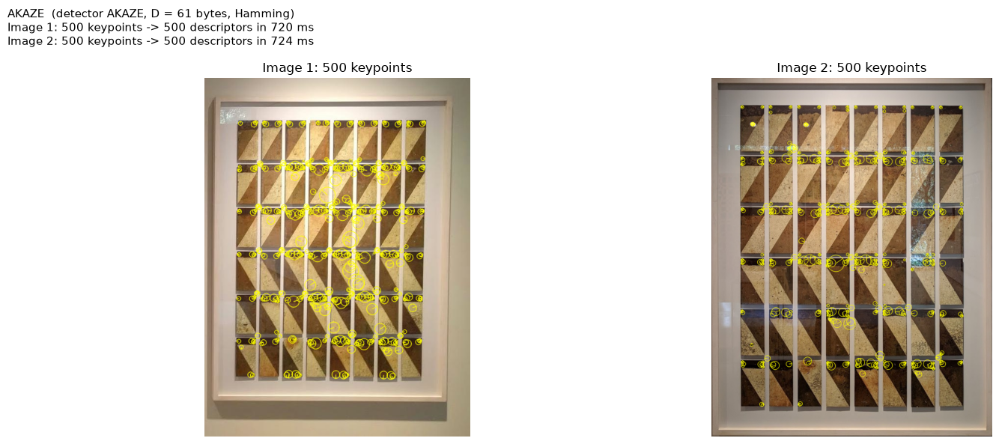

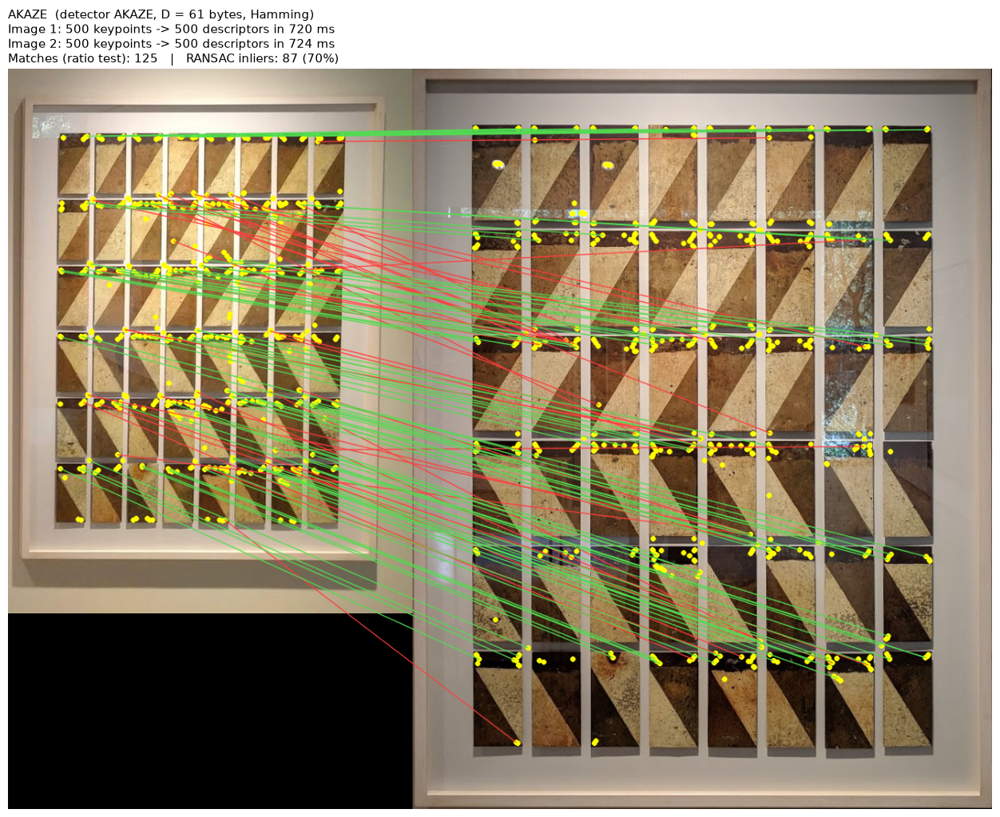

In [32]:
NAME = "sift"
show_keypoints(NAME)
if len(imgs) == 2:
    show_matches(NAME)